In [100]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

from tqdm.auto import tqdm
from pathlib import Path
from typing import Iterator, Mapping, Sequence, TypedDict

In [2]:
datasource_path = Path("..")/"src/04_homework/course_lead_scoring_2026.csv"

In [35]:
course_lead_scoring_df = pd.read_csv(datasource_path)

print(course_lead_scoring_df.shape)
course_lead_scoring_df.head()

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [38]:
print(course_lead_scoring_df["converted"].isna().sum())
course_lead_scoring_df[course_lead_scoring_df["converted"]==np.nan]

0


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted


In [43]:
course_lead_scoring_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [146]:
for ele in course_lead_scoring_df.select_dtypes("str").columns:
    print(f"{ele} (object)", f"\nNA sum: {course_lead_scoring_df[ele].isna().sum()}")
    df[ele] = course_lead_scoring_df[ele].fillna("NA")

for ele in course_lead_scoring_df.drop(columns=["converted"]).select_dtypes(np.number).columns:
    print(f"{ele} (numeric)", f"\nNA sum: {course_lead_scoring_df[ele].isna().sum()}")
    df[ele] = course_lead_scoring_df[ele].fillna(0)    

lead_source (object) 
NA sum: 148
industry (object) 
NA sum: 240
employment_status (object) 
NA sum: 194
location (object) 
NA sum: 208
annual_income (numeric) 
NA sum: 369
number_of_courses_viewed (numeric) 
NA sum: 0
interaction_count (numeric) 
NA sum: 0
lead_score (numeric) 
NA sum: 35


In [147]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train.shape, df_val.shape, df_test.shape

((3000, 9), (1000, 9), (1000, 9))

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [46]:
df.select_dtypes(np.number).head()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,88160.0,3,4,0.64,1
1,72688.0,3,7,0.72,1
2,44697.0,3,4,0.58,1
3,0.0,3,6,0.57,0
4,24062.0,4,5,0.62,1


In [ ]:
def auc_eval(score: pd.Series, y: pd.Series) -> float:
    df = pd.DataFrame(data={"score": score, "target": y}).sort_values(by="score", ascending=True).reset_index(drop=True)

    return float(roc_auc_score(y_true=df["target"], y_score=df["score"]))

In [56]:
for ele in df.select_dtypes(np.number):
    print(f"AUC {ele}: {auc_eval(df_train[ele].fillna(0), df_train["converted"])}")

AUC annual_income: 0.6081977776250831
AUC number_of_courses_viewed: 0.7229894623989618
AUC interaction_count: 0.7649203047563227
AUC lead_score: 0.7882254810906102
AUC converted: 1.0



### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [49]:
# from sklearn.feature_extraction import DictVectorizer

features_list = df_train.drop(columns="converted").columns.to_list()
# print(features_list)

# for ele in df_train.select_dtypes(str).columns:
#     display(df_train[ele].value_counts(dropna=False))

dv = DictVectorizer(sparse=False)

train_dict = df_train[features_list].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

In [28]:
display(train_dict[0])
display({key: value for key, value in zip(dv.get_feature_names_out(), X_train[0])})

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

{'annual_income': np.float64(80198.0),
 'employment_status': np.float64(0.0),
 'employment_status=employed': np.float64(1.0),
 'employment_status=self_employed': np.float64(0.0),
 'employment_status=student': np.float64(0.0),
 'employment_status=unemployed': np.float64(0.0),
 'industry': np.float64(0.0),
 'industry=education': np.float64(0.0),
 'industry=finance': np.float64(0.0),
 'industry=healthcare': np.float64(0.0),
 'industry=manufacturing': np.float64(0.0),
 'industry=retail': np.float64(0.0),
 'industry=technology': np.float64(1.0),
 'interaction_count': np.float64(9.0),
 'lead_score': np.float64(0.91),
 'lead_source': np.float64(0.0),
 'lead_source=events': np.float64(0.0),
 'lead_source=organic_search': np.float64(0.0),
 'lead_source=paid_ads': np.float64(1.0),
 'lead_source=referral': np.float64(0.0),
 'lead_source=social_media': np.float64(0.0),
 'location': np.float64(0.0),
 'location=africa': np.float64(0.0),
 'location=asia': np.float64(1.0),
 'location=europe': np.float

In [65]:
# from sklearn.preprocessing import OneHotEncoder

cat_features_list = df_train.drop(columns="converted").select_dtypes("str").columns.to_list()
# print(cat_features_list)

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown='ignore')
X_train_cat = ohe.fit_transform(df_train[cat_features_list].values)

In [26]:
display(df_train.select_dtypes("str").head(0))
display({key: value for key, value in zip(ohe.get_feature_names_out(), X_train_cat[0])})

,lead_source,industry,employment_status,location


{'x0_events': np.float64(0.0),
 'x0_organic_search': np.float64(0.0),
 'x0_paid_ads': np.float64(1.0),
 'x0_referral': np.float64(0.0),
 'x0_social_media': np.float64(0.0),
 'x0_nan': np.float64(0.0),
 'x1_education': np.float64(0.0),
 'x1_finance': np.float64(0.0),
 'x1_healthcare': np.float64(0.0),
 'x1_manufacturing': np.float64(0.0),
 'x1_retail': np.float64(0.0),
 'x1_technology': np.float64(1.0),
 'x1_nan': np.float64(0.0),
 'x2_employed': np.float64(1.0),
 'x2_self_employed': np.float64(0.0),
 'x2_student': np.float64(0.0),
 'x2_unemployed': np.float64(0.0),
 'x2_nan': np.float64(0.0),
 'x3_africa': np.float64(0.0),
 'x3_asia': np.float64(1.0),
 'x3_europe': np.float64(0.0),
 'x3_north_america': np.float64(0.0),
 'x3_south_america': np.float64(0.0),
 'x3_nan': np.float64(0.0)}

In [66]:
# from sklearn.linear_model import LogisticRegression

model_1a = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model_1a.fit(X_train, df_train["converted"])

model_1b = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model_1b.fit(np.column_stack([X_train_cat, df_train.drop(columns="converted").select_dtypes(np.number)])
, df_train["converted"])

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [67]:
val_dict = df_val[features_list].to_dict(orient="records")
X_val = dv.fit_transform(val_dict)

round(auc_eval(score=model_1a.predict_proba(X_val)[::, 1], y=df_val["converted"]), 3)

0.732

In [68]:
X_val_cat = ohe.fit_transform(df_val[cat_features_list].values)
X_val_ohe = np.column_stack([X_val_cat, df_val.drop(columns="converted").select_dtypes(np.number)])

round(auc_eval(score=model_1b.predict_proba(X_val_ohe)[::, 1], y=df_val["converted"]), 3)

0.732


### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83


In [ ]:
y_pred_val = model_1b.predict_proba(X_val_ohe)[::, 1]
# y_pred_val

In [ ]:
def conf_matrix_tresholds(y: Sequence[float], y_pred: Sequence[float]) -> pd.DataFrame:
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y == 1)
        actual_negative = (y == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        
        scores.append((t, tp, fp, fn, tn))
    
    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)
    df_scores["precision"] = df_scores["tp"] / df_scores[["tp", "fp"]].sum(axis=1)
    df_scores["recall"] = df_scores["tp"] / df_scores[["tp", "fn"]].sum(axis=1)
    df_scores["f1"] = 2 * (df_scores["precision"] * df_scores["recall"]) / df_scores[["precision", "recall"]].sum(axis=1)
    
    return df_scores

In [ ]:
conf_matrix_df = conf_matrix_tresholds(y=df_val["converted"], y_pred=y_pred_val)
conf_matrix_df["abs_diff"] = abs(conf_matrix_df["precision"] - conf_matrix_df["recall"])

conf_matrix_df.head()

,threshold,tp,fp,fn,tn,precision,recall,f1,abs_diff
0,0.00,586,414,0,0,0.586,1.0,0.738966,0.414
1,0.01,586,414,0,0,0.586,1.0,0.738966,0.414
2,0.02,586,414,0,0,0.586,1.0,0.738966,0.414
3,0.03,586,414,0,0,0.586,1.0,0.738966,0.414
4,0.04,586,414,0,0,0.586,1.0,0.738966,0.414


In [98]:
conf_matrix_df.loc[conf_matrix_df.index == conf_matrix_df["abs_diff"].idxmin()]

,threshold,tp,fp,fn,tn,precision,recall,f1,abs_diff
63,0.63,426,155,160,259,0.733219,0.726962,0.730077,0.006256


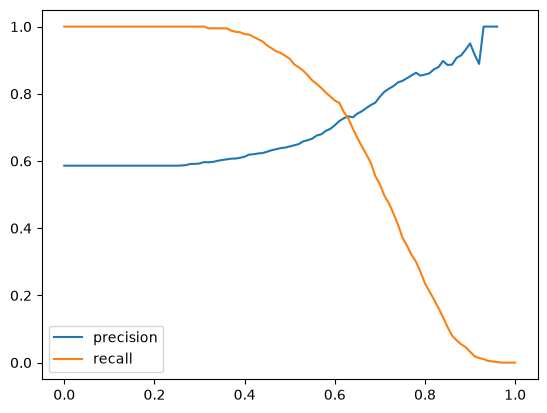

In [ ]:
plt.plot(conf_matrix_df.threshold, conf_matrix_df["precision"], label='precision')
plt.plot(conf_matrix_df.threshold, conf_matrix_df["recall"], label='recall')
plt.legend()

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81


In [93]:
conf_matrix_df.loc[conf_matrix_df.index == conf_matrix_df["f1"].idxmax()]

,threshold,tp,fp,fn,tn,precision,recall,abs_diff,f1
41,0.41,572,352,14,62,0.619048,0.976109,0.357062,0.757616


### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060


In [190]:
def _fit_logistic_regression(X: pd.DataFrame, y: pd.Series, *,  solver='liblinear', C=1.0, max_iter=1000):
    model = LogisticRegression(solver=solver, C=C, max_iter=max_iter)
    
    return model.fit(X, y)

def _predict_probability(model_object, X: pd.DataFrame) -> np.ndarray:
    return model_object.predict_proba(X)[::, 1]

def _auc_eval(score: pd.Series, y: pd.Series) -> float:
    df = pd.DataFrame(data={"score": score, "target": y}).sort_values(by="score", ascending=True).reset_index(drop=True)

    return float(roc_auc_score(y_true=df["target"], y_score=df["score"]))

def cross_validation(
        X: pd.DataFrame,
        y: pd.Series,
        *,
        n_splits: int = 5,
        random_state: int = 1,
        C=1.0
    ) -> pd.DataFrame:
    
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    folds = []

    X = X.reset_index(drop=True)
    y = y.reset_index(drop=True)

    for fold, (train_index, valid_index) in enumerate(kfold.split(X), 1):
        X_train = X.iloc[train_index]
        X_valid = X.iloc[valid_index]
        y_train = y.iloc[train_index]
        y_valid = y.iloc[valid_index]

        result = _fit_logistic_regression(X=X_train, y=y_train, C=C)
        train_probability = pd.Series(_predict_probability(result, X_train), index=X_train.index)
        valid_probability = pd.Series(_predict_probability(result, X_valid), index=X_valid.index)

        folds.append(
            {
                "fold": int(fold),
                "rate_default_train": float(y_train.sum()/len(y_train)),
                "rate_default_valid": float(y_valid.sum()/len(y_valid)),
                "auc_train": _auc_eval(score=train_probability, y=y_train),
                "auc_valid": _auc_eval(score=valid_probability, y=y_valid),
            }
        )

    return pd.DataFrame(folds)

In [189]:
cat_features_list = df_full_train.drop(columns="converted").select_dtypes("str").columns.to_list()
# print(cat_features_list)
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown='ignore')
X_full_train_cat = ohe.fit_transform(df_full_train[cat_features_list].values)
X_full_train = pd.concat(
    [
        pd.DataFrame(X_full_train_cat, columns=ohe.get_feature_names_out(), index=df_full_train.index),
        df_full_train.drop(columns="converted").select_dtypes(np.number),
    ],
    axis=1
)

cross_validation_df = cross_validation(
    X=X_full_train,
    y=df_full_train["converted"]
)

cross_validation_df

,fold,rate_default_train,rate_default_valid,auc_train,auc_valid
0,1,0.578125,0.58125,0.734205,0.730534
1,2,0.582500,0.56375,0.733285,0.729744
2,3,0.577187,0.58500,0.729663,0.736349
3,4,0.580000,0.57375,0.729833,0.741303
4,5,0.575937,0.59000,0.734572,0.721043


In [188]:
cross_validation_df["auc_valid"].std()

np.float64(0.007624667909562257)

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [192]:
cat_features_list = df_full_train.drop(columns="converted").select_dtypes("str").columns.to_list()
# print(cat_features_list)
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown='ignore')
X_full_train_cat = ohe.fit_transform(df_full_train[cat_features_list].values)
X_full_train = pd.concat(
    [
        pd.DataFrame(X_full_train_cat, columns=ohe.get_feature_names_out(), index=df_full_train.index),
        df_full_train.drop(columns="converted").select_dtypes(np.number),
    ],
    axis=1
)
for C in [0.000001, 0.001, 1]:
    cross_validation_df = cross_validation(
        X=X_full_train,
        y=df_full_train["converted"],
        C=C
    )

    print(f"C: {C}")
    display(cross_validation_df)
    print(f"mean AUC valid: {cross_validation_df["auc_valid"].mean()}")
    print("#"*50)
    print("\n")

C: 1e-06


,fold,rate_default_train,rate_default_valid,auc_train,auc_valid
0,1,0.578125,0.58125,0.621437,0.594100
1,2,0.582500,0.56375,0.610627,0.640207
2,3,0.577187,0.58500,0.620001,0.600157
3,4,0.580000,0.57375,0.611260,0.636453
4,5,0.575937,0.59000,0.617538,0.612753


mean AUC valid: 0.6167342322155155
##################################################


C: 0.001


,fold,rate_default_train,rate_default_valid,auc_train,auc_valid
0,1,0.578125,0.58125,0.757056,0.750422
1,2,0.582500,0.56375,0.751294,0.747686
2,3,0.577187,0.58500,0.750812,0.758277
3,4,0.580000,0.57375,0.745408,0.758394
4,5,0.575937,0.59000,0.746382,0.731191


mean AUC valid: 0.7491937443033685
##################################################


C: 1


,fold,rate_default_train,rate_default_valid,auc_train,auc_valid
0,1,0.578125,0.58125,0.734205,0.730534
1,2,0.582500,0.56375,0.733285,0.729744
2,3,0.577187,0.58500,0.729663,0.736349
3,4,0.580000,0.57375,0.729833,0.741303
4,5,0.575937,0.59000,0.734572,0.721043


mean AUC valid: 0.7317947677238934
##################################################


